# Small bumps: artifacts, geology or detector?

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
import seafloor as sf

lon, lat, z, ship, dx, dy = sf.load_clean()
DX = float(np.mean(dx))
clusters = np.load(sf.DATA_DIR / "clusters.npy")

zf = np.where(np.isnan(z), np.nanmedian(z), z)
zs = ndimage.gaussian_filter(zf, 1500 / DX)
r = int(3000 / DX); disk = np.hypot(*np.mgrid[-r:r+1, -r:r+1]) <= r
is_max = ndimage.maximum_filter(zs, footprint=disk) == zs
k = 4
base = ndimage.percentile_filter(zs[::k, ::k], 10, size=int(2 * 15000 / (DX * k)) + 1)
base = ndimage.zoom(base, (zs.shape[0] / base.shape[0], zs.shape[1] / base.shape[1]), order=1)[:zs.shape[0], :zs.shape[1]]
height = zs - base
edge = int(15000 / DX / 3)
valid = ~np.isnan(z); valid[:edge] = valid[-edge:] = False; valid[:, :edge] = valid[:, -edge:] = False
ii, jj = np.nonzero(is_max & valid & (height > 100))
H, S, CL = height[ii, jj], ship[ii, jj], clusters[ii, jj]

w = np.cos(np.deg2rad(lat))[:, None] * np.ones_like(z)
KM2_PER_W = 578_147 / (w * valid).sum()
def density(det_mask, cell_mask):
    return det_mask.sum() / ((w * cell_mask).sum() * KM2_PER_W) * 1e4
BINS = [(100, 300), (300, 500), (500, 1000), (1000, 1e9)]
print(f"{len(H)} detections")

854 detections


In [2]:
print(f"{'':16s}{'height (m)':>12s}{'ship':>8s}{'sat':>8s}{'ratio':>8s}")
res = {}
for name, cells, dets in [("whole region", valid, np.ones_like(H, bool)),
                          ("plains only", valid & (clusters == 1), CL == 1)]:
    for lo, hi in BINS:
        m = dets & (H >= lo) & (H < hi)
        a, b = density(m & S, cells & ship), density(m & ~S, cells & ~ship)
        res[(name, lo)] = a / b if b else np.nan
        print(f"{name:16s}{lo:>6.0f}–{hi if hi < 1e8 else '+':<5}{a:8.2f}{b:8.2f}{a / b if b else np.nan:8.2f}")

                  height (m)    ship     sat   ratio
whole region       100–300      1.90    4.56    0.42
whole region       300–500      1.84    2.92    0.63
whole region       500–1000     3.94    3.41    1.16
whole region      1000–+        6.33    5.05    1.25
plains only        100–300      2.40    5.76    0.42
plains only        300–500      1.53    2.56    0.60
plains only        500–1000     0.95    1.11    0.86
plains only       1000–+        0.25    0.23    1.07


In [3]:
small_sat = (H < 500) & ~S
south_det = lat[ii] < 10
sat_cells = valid & ~ship
south_cells = sat_cells & (lat[:, None] < 10)
d_south = density(small_sat & south_det, south_cells)
d_other = density(small_sat & ~south_det, sat_cells & ~(lat[:, None] < 10))
print(f"Small bumps per 10,000 km², satellite-only: south strip {d_south:.1f}, elsewhere {d_other:.1f}")

Small bumps per 10,000 km², satellite-only: south strip 7.9, elsewhere 7.2


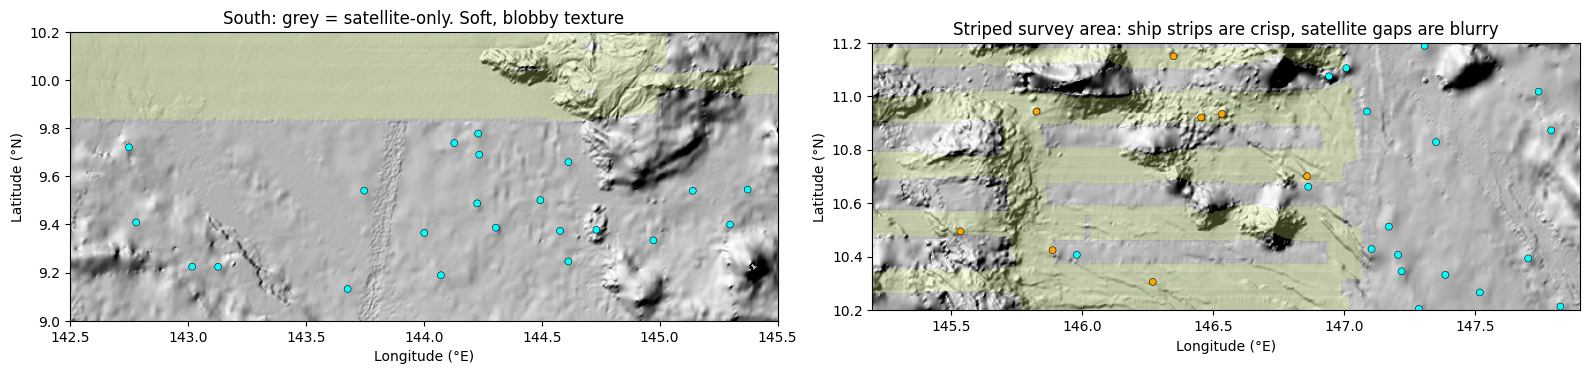

In [4]:
shade = sf.hillshade(zf, dx, dy, exaggeration=6)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (la0, la1, lo0, lo1) in zip(axes, [(9.0, 10.2, 142.5, 145.5), (10.2, 11.2, 145.2, 147.9)]):
    I = (lat >= la0) & (lat <= la1); J = (lon >= lo0) & (lon <= lo1)
    ext = [lo0, lo1, la0, la1]
    ax.imshow(shade[np.ix_(I, J)], origin="lower", extent=ext, cmap="gray", aspect=1.02)
    ax.imshow(np.where(ship[np.ix_(I, J)], 1, np.nan), origin="lower", extent=ext, cmap="Wistia", alpha=0.25, aspect=1.02)
    m = (lat[ii] >= la0) & (lat[ii] <= la1) & (lon[jj] >= lo0) & (lon[jj] <= lo1) & (H < 500)
    ax.scatter(lon[jj[m]], lat[ii[m]], c=np.where(S[m], "orange", "cyan"), s=25, edgecolors="k", linewidths=0.4)
    ax.set(xlabel="Longitude (°E)", ylabel="Latitude (°N)")
axes[0].set_title("South: grey = satellite-only. Soft, blobby texture")
axes[1].set_title("Striped survey area: ship strips are crisp, satellite gaps are blurry")
fig.tight_layout(); fig.savefig(sf.FIG_DIR / "07_small_bumps_zoom.png", dpi=200); plt.show()

In [5]:
print("KEY NUMBERS")
print(f"  100–300 m bumps, ship ÷ satellite density: whole region {res[('whole region', 100)]:.2f}, plains only {res[('plains only', 100)]:.2f}")
print(f"  Small satellite bumps per 10,000 km²: south {d_south:.1f} vs elsewhere {d_other:.1f}")

KEY NUMBERS
  100–300 m bumps, ship ÷ satellite density: whole region 0.42, plains only 0.42
  Small satellite bumps per 10,000 km²: south 7.9 vs elsewhere 7.2
